<a href="https://colab.research.google.com/github/myanh-tran/BananaHack-2026---cat-steals-socks/blob/ngu/Hackathon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import re
def clean_format(raw_text):
    cleaned = re.sub(r'[^A-Z0-9]', "", raw_text.upper())
    if len(cleaned)<7 or len(cleaned) >9:
        return cleaned
    formatted = list(cleaned)
    char_to_num = {"O":"0", "I":"1","Z":"2","S":"5", "B":"8","G":"6","T":"1","Q":"0","J":"4","D":"0", "A":"4"}
    num_to_char= {'0': 'O', '1': 'I', '2': 'Z', '5': 'S', '8': 'B', '6': 'G'}

    for i in range(2):
        if formatted[i] in char_to_num:
            formatted[i] = char_to_num[formatted[i]]
    if formatted[2] in num_to_char:
        formatted[2] = num_to_char[formatted[2]]
    for i in range(2):                      # 2 ký tự đầu: số
        if formatted[i] in char_to_num:
            formatted[i] = char_to_num[formatted[i]]

    if formatted[2] in num_to_char:         # ký tự thứ 3: chữ
        formatted[2] = num_to_char[formatted[2]]

    if formatted[3] in char_to_num:         # ký tự thứ 3: chữ
        formatted[3] = char_to_num[formatted[3]]

    # từ ký tự thứ 5 trở đi: toàn số
    for i in range(4, len(formatted)):
        if formatted[i] in char_to_num:
            formatted[i] = char_to_num[formatted[i]]
    return "".join(formatted)
    return "".join(formatted)
print(clean_format("29A-I23.4S")) # Kết quả: 29A12345 (Sửa I->1, S->5, xóa dấu)
print(clean_format("3OA-12345"))  # Kết quả: 30A12345 (Sửa O->0 ở mã tỉnh)

29A12345
30A12345


In [3]:
pip install fuzzywuzzy

In [4]:
from fuzzywuzzy import fuzz
def match_plate(ocr_plate, resident_db, threshold=85):
    best_match = None
    highest_score = 0
    for db_plate in resident_db:
        score = fuzz.ratio(ocr_plate,db_plate)
        if score >highest_score:
            highest_score = score
            best_match = db_plate
    if highest_score == 100:
        return best_match, highest_score, "CHÍNH XÁC HOÀN TOÀN"
    elif highest_score >= threshold:
        return best_match, highest_score, "KHỚP GẦN ĐÚNG (Có thể OCR sai 1-2 nét nhỏ)"
    else:
        return None, highest_score, "KHÔNG TÌM THẤY TRONG CSDL"

# Test thử:
db_cu_dan = ["30A12345", "29B98765", "51F112233"]

# Trường hợp 1: OCR đọc sai số 8 thành chữ B, hàm clean ở trên chưa quét hết được
print(match_plate("30A12345", db_cu_dan))
# -> Điểm 100, khớp 30A12345

# Trường hợp 2: Bị thiếu/sai 1 ký tự (OCR bị lóa mất 1 số)
print(match_plate("29B9876", db_cu_dan))
# -> Điểm 93, khớp 29B98765

# Trường hợp 3: Biển số xe khách lạ
print(match_plate("99C11111", db_cu_dan))
# -> Điểm dưới threshold, KHÔNG TÌM THẤY

('30A12345', 100, 'CHÍNH XÁC HOÀN TOÀN')
('29B98765', 93, 'KHỚP GẦN ĐÚNG (Có thể OCR sai 1-2 nét nhỏ)')
(None, 25, 'KHÔNG TÌM THẤY TRONG CSDL')


/usr/local/lib/python3.13/dist-packages/fuzzywuzzy/fuzz.py:11: UserWarning: Using slow pure-python SequenceMatcher. Install python-Levenshtein to remove this warning
  warnings.warn('Using slow pure-python SequenceMatcher. Install python-Levenshtein to remove this warning')


In [5]:
import cv2
import numpy as np

def preprocess_plate(image_path):
    # 1. Đọc ảnh
    img = cv2.imread(image_path)

    # 2. Chuyển sang ảnh xám
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 3. Tăng cường độ tương phản cục bộ (CLAHE) - Giúp chữ mờ nổi bật lên
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    # 4. Làm sắc nét ảnh (Sharpening) - Khôi phục các nét chữ bị vỡ, mờ
    # Tạo kernel làm sắc nét (tăng cường điểm trung tâm, giảm xung quanh)
    kernel_sharpen = np.array([
        [ 0, -1,  0],
        [-1,  5, -1],
        [ 0, -1,  0]
    ])
    sharpened = cv2.filter2D(enhanced, -1, kernel_sharpen)

    # 5. Khử nhiễu nhẹ bằng Bilateral Filter thay cho Gaussian Blur
    # Bộ lọc này giúp làm mịn nền nhưng GIỮ LẠI CẠNH CHỮ, không làm mờ chữ
    filtered = cv2.bilateralFilter(sharpened, d=9, sigmaColor=75, sigmaSpace=75)

    # 6. Nhị phân hóa thích nghi (Adaptive Thresholding)
    # Rất tốt cho ảnh mờ/tối vì nó tính ngưỡng theo từng khu vực nhỏ (blockSize=11)
    thresh = cv2.adaptiveThreshold(
        filtered,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        11,
        2
    )

    # 7. (Tùy chọn) Nếu chữ vẫn bị đứt nét, dùng phép giãn nở nhẹ (Dilation) để nối nét
    kernel_dilate = np.ones((1, 1), np.uint8) # Dùng kernel siêu nhỏ 1x1 hoặc 2x2
    thresh = cv2.dilate(thresh, kernel_dilate, iterations=1)

    # Trả về các bước để bạn so sánh
    return img, filtered, thresh

In [6]:
!pip install pytesseract

ERROR: Operation cancelled by user


In [8]:
!pip install easyocr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 41.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 16.7 MB/s eta 0:00:00


Đã tìm thấy 9 ảnh. Bắt đầu xử lý...

--------------------------------------------------
Đang xử lý: 92-la-tinh-nao-thumbnail.jpg
  -> Chuỗi thô OCR: ''
  -> Biển số SẠCH:  ''


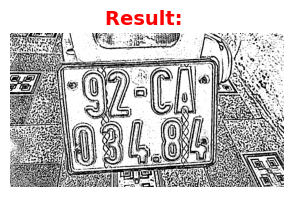

--------------------------------------------------
Đang xử lý: Biển_số_xe_đồng_tháp.jpg
  -> Chuỗi thô OCR: ''
  -> Biển số SẠCH:  ''


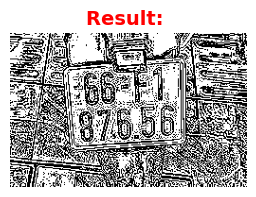

--------------------------------------------------


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Đang xử lý: Screenshot 2026-10-10 165417.png
  -> Chuỗi thô OCR: 'PGC TZCEN'
  -> Biển số SẠCH:  'PGC TZCEN'


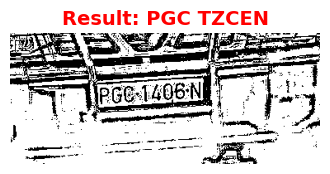

--------------------------------------------------
Đang xử lý: Screenshot 2026-10-10 165448.png
  -> Chuỗi thô OCR: 'VaoxFajAD D'
  -> Biển số SẠCH:  'VaoxFajAD D'


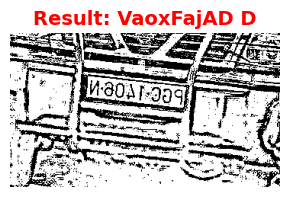

--------------------------------------------------
Đang xử lý: Screenshot 2026-10-10 165555.png
  -> Chuỗi thô OCR: '44KA#sEdBEJA44c1'
  -> Biển số SẠCH:  '44KA#sEdBEJA44c1'


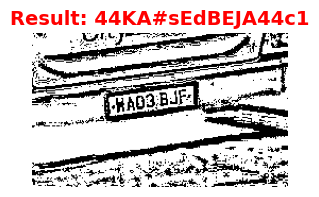

--------------------------------------------------
Đang xử lý: Screenshot 2026-10-10 165702.png
  -> Chuỗi thô OCR: '509412.55'
  -> Biển số SẠCH:  '509412.55'


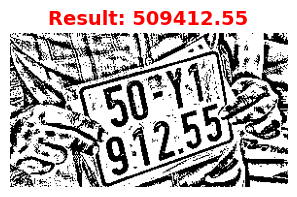

--------------------------------------------------
Đang xử lý: Screenshot 2026-10-10 165719.png
  -> Chuỗi thô OCR: '3ok;45670'
  -> Biển số SẠCH:  '3ok;45670'


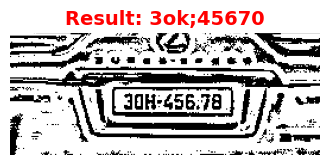

--------------------------------------------------
Đang xử lý: Screenshot 2026-10-10 165808.png
  -> Chuỗi thô OCR: '0'
  -> Biển số SẠCH:  '0'


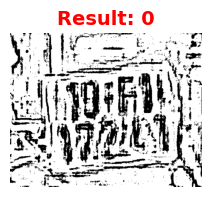

--------------------------------------------------
Đang xử lý: Screenshot 2026-10-10 165827.png
  -> Chuỗi thô OCR: ''
  -> Biển số SẠCH:  ''


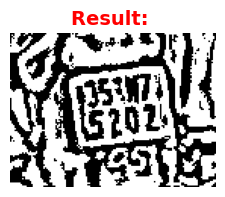

--------------------------------------------------


In [10]:
import glob
import cv2
import matplotlib.pyplot as plt
import easyocr
import re

# Khởi tạo EasyOCR Reader
reader = easyocr.Reader(['en'], gpu=False)

duong_dan_folder = "/content/bien/*.*"
danh_sach_anh = sorted(f for f in glob.glob(duong_dan_folder)
                       if f.lower().endswith(('.jpg', '.jpeg', '.png')))



if len(danh_sach_anh) == 0:
    print("Không tìm thấy ảnh nào! Bạn kiểm tra lại folder '/content/bien_so' nhé.")
else:
    print(f"Đã tìm thấy {len(danh_sach_anh)} ảnh. Bắt đầu xử lý...\n")
    print("-" * 50)

    for image_path in danh_sach_anh:
        # Tiền xử lý
        img_goc, img_xam, img_xu_ly = preprocess_plate(image_path)

        # Đọc chữ bằng EasyOCR (Đọc trên ảnh nhị phân)
        ket_qua_ocr = reader.readtext(img_xu_ly, detail=0)
        chuoi_tho = "".join(ket_qua_ocr)

        # Làm sạch chuỗi
        bien_so_cuoi_cung = chuoi_tho

        # In kết quả ra màn hình
        print(f"Đang xử lý: {image_path.split('/')[-1]}")
        print(f"  -> Chuỗi thô OCR: '{chuoi_tho}'")
        print(f"  -> Biển số SẠCH:  '{bien_so_cuoi_cung}'")

        # Trực quan hóa
        plt.figure(figsize=(4, 2))
        plt.imshow(img_xu_ly, cmap='gray')
        plt.title(f"Result: {bien_so_cuoi_cung}", color='red', fontsize=14, fontweight='bold')
        plt.axis('off')
        plt.show()
        print("-" * 50)

##Theo hướng MNIST

In [1]:
# ===== BƯỚC 1: Train base trên MNIST gốc =====
import tensorflow as tf

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.astype('float32') / 255.0
x_test  = x_test.astype('float32') / 255.0
x_train = x_train[..., None]   # (60000, 28, 28, 1)
x_test  = x_test[..., None]

model = tf.keras.Sequential([
    tf.keras.layers.Input((28, 28, 1)),
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPool2D(),
    tf.keras.layers.Conv2D(64, 3, activation='relu'),
    tf.keras.layers.MaxPool2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax'),   # 10 lớp SỐ
])
model.compile('adam', 'sparse_categorical_crossentropy', metrics=['acc'])

# Train ~5 epochs → ~5 phút trên CPU, ~30 giây trên Colab GPU
model.fit(x_train, y_train, epochs=5, batch_size=128,
          validation_data=(x_test, y_test))

model.save("mnist_base.keras")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - acc: 0.9395 - loss: 0.2085 - val_acc: 0.9820 - val_loss: 0.0587
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - acc: 0.9815 - loss: 0.0600 - val_acc: 0.9870 - val_loss: 0.0378
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - acc: 0.9872 - loss: 0.0407 - val_acc: 0.9878 - val_loss: 0.0371
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - acc: 0.9897 - loss: 0.0324 - val_acc: 0.9869 - val_loss: 0.0392
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - acc: 0.9926 - loss: 0.0246 - val_acc: 0.9902 - val_loss: 0.0286


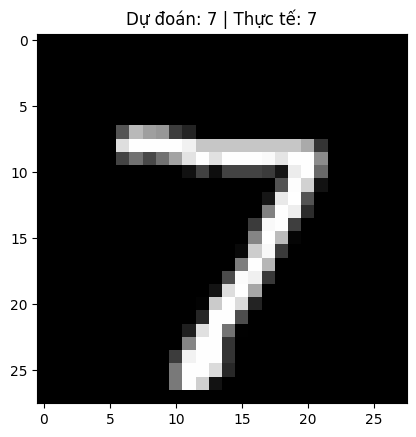

In [2]:
# Load lại model
model = tf.keras.models.load_model("mnist_base.keras")

# Lấy 1 ảnh test
import matplotlib.pyplot as plt
i = 0
img = x_test[i]                      # shape (28, 28, 1)
pred = model.predict(img[None], verbose=0)   # (1, 10)
predicted = pred.argmax()
truth = y_test[i]

plt.imshow(img.squeeze(), cmap='gray')
plt.title(f"Dự đoán: {predicted} | Thực tế: {truth}")
plt.show()

In [47]:
import cv2
import numpy as np

def crop_plate(img):
    """Tự động cắt sát vùng biển số xe bằng cách tìm khung Contour lớn nhất."""
    if img is None:
        return None
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img

    # Nhị phân hóa Otsu để tách nền biển sáng
    _, th = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Đóng các lỗ hổng nhỏ bằng phép Morphological Close
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 5))
    th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, kernel)

    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        return img

    # Lấy vùng có diện tích lớn nhất
    c = max(cnts, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(c)

    # Loại bỏ nhiễu nếu diện tích bounding box quá bé so với ảnh gốc
    if w * h < 0.05 * img.shape[0] * img.shape[1]:
        return img
    return img[y:y+h, x:x+w]

In [51]:
import cv2, numpy as np

TARGET_H = 200

def preprocess(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img
    s = TARGET_H / gray.shape[0]
    gray = cv2.resize(gray, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC)
    p = int(0.12 * TARGET_H)
    bg = int(np.percentile(gray, 90))
    gray = cv2.copyMakeBorder(gray, p, p, p, p, cv2.BORDER_CONSTANT, value=bg)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    bw = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                               cv2.THRESH_BINARY_INV, 41, 12)
    return bw, s, p          # trả thêm s và p

def to_original(box, s, p):
    x, y, w, h = box
    return (int((x - p) / s), int((y - p) / s), int(w / s), int(h / s))

def drop_outliers(row, med, thr=0.35):
    row = list(row)
    while len(row) > 3:
        cx = np.array([c[0] + c[2] / 2 for c in row])
        cy = np.array([c[1] + c[3] / 2 for c in row])
        k, b = np.polyfit(cx, cy, 1)
        res = np.abs(cy - (k * cx + b))
        j = res.argmax()
        if res[j] <= thr * med:
            break
        row.pop(j)
    return row

def find_chars(img):
    bw,s,p = preprocess(img)          # bw đã được đệm viền, box tính theo ảnh này
    bw = cv2.morphologyEx(bw, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(bw, connectivity=8)

    cand = []
    for i in range(1, n):
        x, y, w, h, a = stats[i]
        if not (0.15 * TARGET_H <= h <= 0.75 * TARGET_H): continue
        if not (0.12 <= w / h <= 1.2):                    continue
        if a / (w * h) < 0.2:                             continue
        cand.append((x, y, w, h))
    if len(cand) < 2:
        return bw, cand,s,p

    med = np.median([c[3] for c in cand])
    cand = [c for c in cand if 0.7 * med <= c[3] <= 1.35 * med]

    # chia 1 hoặc 2 dòng theo gap lớn nhất của tâm y
    cy = np.array([c[1] + c[3] / 2 for c in cand])
    order = np.argsort(cy)
    gaps = np.diff(cy[order])
    if len(gaps) and gaps.max() > 0.5 * med:
        k = gaps.argmax()
        rows = [[cand[j] for j in order[:k + 1]], [cand[j] for j in order[k + 1:]]]
    else:
        rows = [cand]

    out = []
    for r in rows:
        r = drop_outliers(r, med)
        out += sorted(r, key=lambda c: c[0])
    return bw, out,s,p

In [36]:
def sort_chars_by_line(chars):
    """Gom ký tự thành 2 dòng bằng k-means trên tâm y."""
    if len(chars) < 2:
        return sorted(chars, key=lambda c: c[0])

    ys = np.array([[c[1] + c[3]/2] for c in chars], dtype=np.float32)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    _, labels, centers = cv2.kmeans(ys, 2, None, criteria, 10, cv2.KMEANS_PP_CENTERS)
    labels = labels.flatten()

    # Tâm y nhỏ = dòng trên
    top_idx = 0 if centers[0][0] < centers[1][0] else 1
    top = [chars[i] for i in range(len(chars)) if labels[i] == top_idx]
    bot = [chars[i] for i in range(len(chars)) if labels[i] != top_idx]

    top.sort(key=lambda c: c[0])   # sort theo x
    bot.sort(key=lambda c: c[0])
    return top + bot


In [53]:
def crop_chars(bw, chars):
    crops = []
    for x, y, w, h in chars:
        sub = bw[y:y+h, x:x+w].copy()

        # 1) bỏ nét của ký tự láng giềng: chỉ giữ component lớn nhất trong hộp
        n, lab, st, _ = cv2.connectedComponentsWithStats(sub, connectivity=8)
        if n > 1:
            k = 1 + np.argmax(st[1:, cv2.CC_STAT_AREA])
            sub = ((lab == k) * 255).astype(np.uint8)

        # 2) giữ tỉ lệ, chữ cao 20px
        s = 20.0 / max(w, h)
        sub = cv2.resize(sub, (max(1, round(w * s)), max(1, round(h * s))),
                         interpolation=cv2.INTER_AREA)

        # 3) đặt vào canvas 28x28, căn theo khối tâm như MNIST
        canvas = np.zeros((28, 28), np.uint8)
        oy, ox = (28 - sub.shape[0]) // 2, (28 - sub.shape[1]) // 2
        canvas[oy:oy+sub.shape[0], ox:ox+sub.shape[1]] = sub
        m = cv2.moments(canvas)
        if m["m00"] > 0:
            cx, cy = m["m10"] / m["m00"], m["m01"] / m["m00"]
            M = np.float32([[1, 0, 14 - cx], [0, 1, 14 - cy]])
            canvas = cv2.warpAffine(canvas, M, (28, 28))
        crops.append(canvas)
    return crops

Đã tải mô hình nhận dạng mnist_base.keras thành công!
Đã tìm thấy 11 ảnh. Bắt đầu xử lý và nhận dạng...

--------------------------------------------------
Ảnh 1791624458175_46226632464972839_g7345200886465729132_b7bb2d884a3da049ffb70242a4a45a7c.jpg: Tìm được 2 ký tự
 -> Biển số nhận dạng thô: 42
 -> Biển số chuẩn hóa:    42


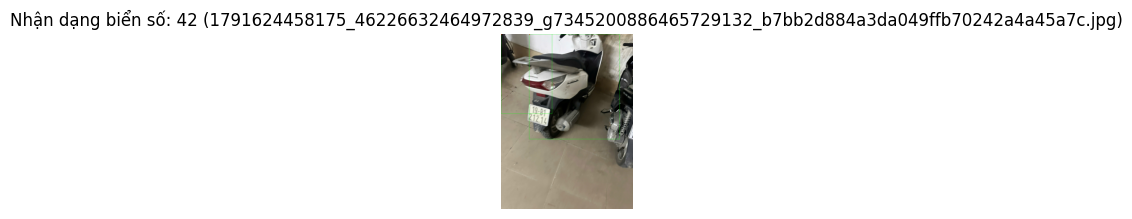

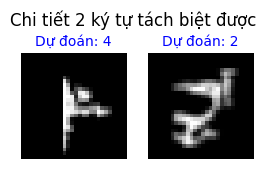

--------------------------------------------------
Ảnh 92-la-tinh-nao-thumbnail.jpg: Tìm được 10 ký tự
 -> Biển số nhận dạng thô: 9251103484
 -> Biển số chuẩn hóa:    9251103484


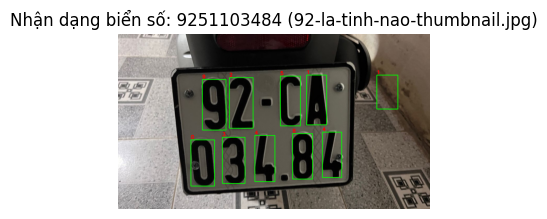

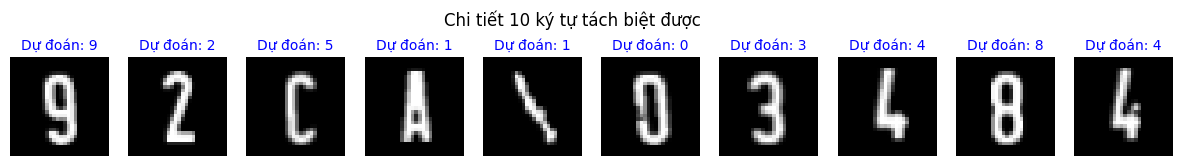

--------------------------------------------------
Ảnh Biển_số_xe_đồng_tháp.jpg: Tìm được 8 ký tự
 -> Biển số nhận dạng thô: 66187656
 -> Biển số chuẩn hóa:    66187656


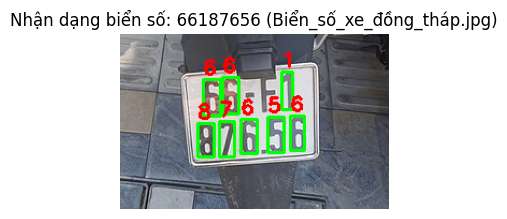

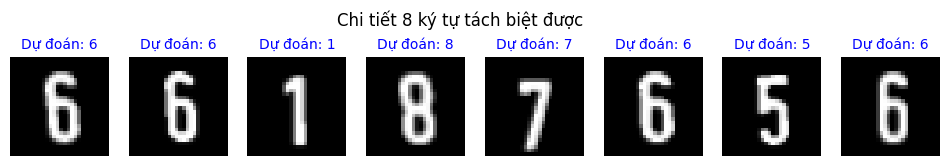

--------------------------------------------------
Ảnh Screenshot 2026-10-10 165417.png: Tìm được 1 ký tự
 -> Biển số nhận dạng thô: 1
 -> Biển số chuẩn hóa:    1


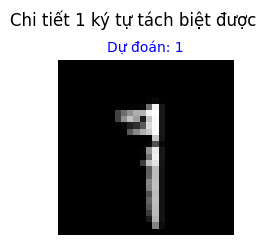

--------------------------------------------------
Ảnh Screenshot 2026-10-10 165448.png: Tìm được 2 ký tự
 -> Biển số nhận dạng thô: 11
 -> Biển số chuẩn hóa:    11


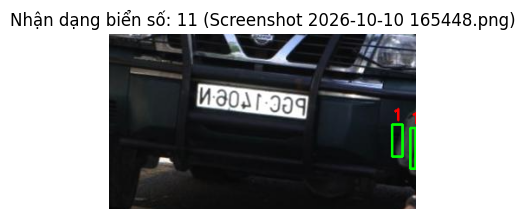

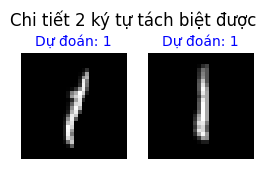

--------------------------------------------------
Ảnh Screenshot 2026-10-10 165702.png: Tìm được 6 ký tự
 -> Biển số nhận dạng thô: 715251
 -> Biển số chuẩn hóa:    715251


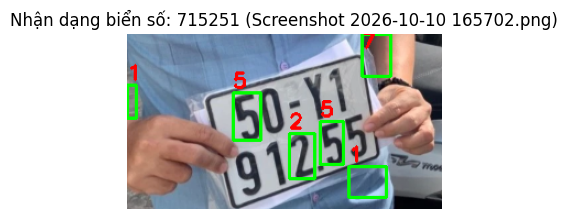

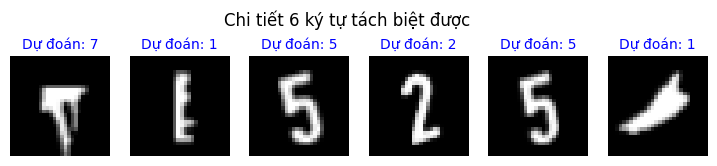

--------------------------------------------------
Ảnh Screenshot 2026-10-10 165719.png: Tìm được 3 ký tự
 -> Biển số nhận dạng thô: 111
 -> Biển số chuẩn hóa:    111


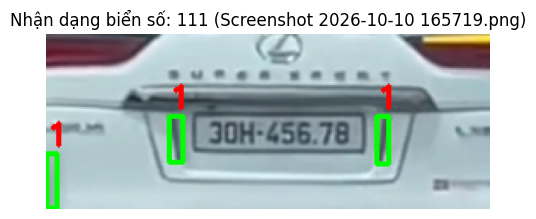

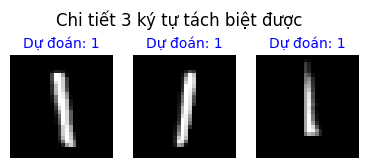

--------------------------------------------------
Ảnh Screenshot 2026-10-10 165808.png: Tìm được 9 ký tự
 -> Biển số nhận dạng thô: 198117241
 -> Biển số chuẩn hóa:    198117241


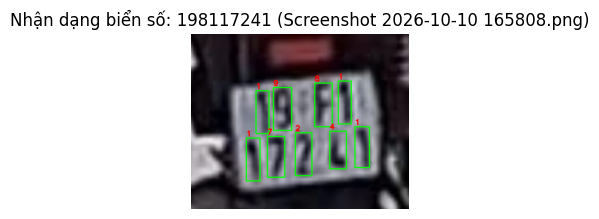

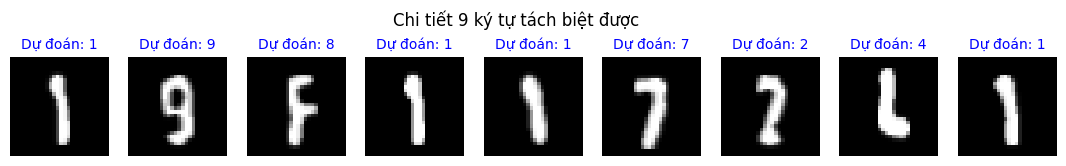

--------------------------------------------------
Ảnh Screenshot 2026-10-10 165827.png: Tìm được 5 ký tự
 -> Biển số nhận dạng thô: 52021
 -> Biển số chuẩn hóa:    52021


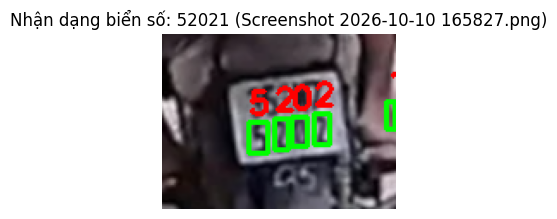

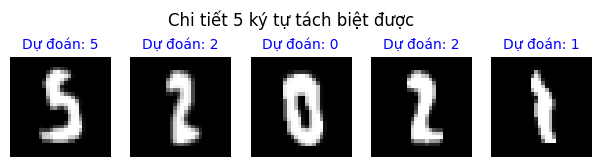

--------------------------------------------------
Ảnh tot.png: Tìm được 10 ký tự
 -> Biển số nhận dạng thô: 9254103484
 -> Biển số chuẩn hóa:    9254103484


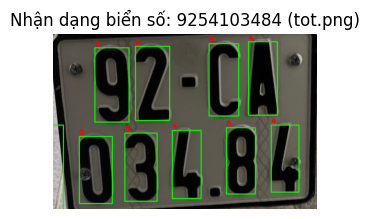

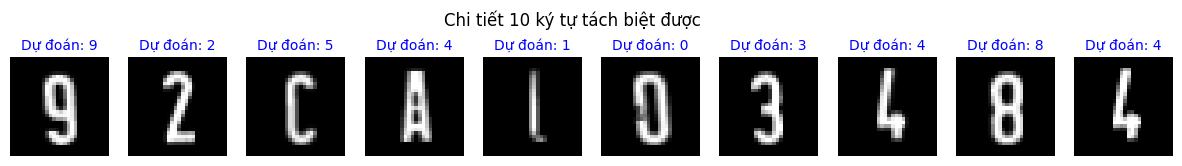

--------------------------------------------------
Ảnh tot1.png: Tìm được 9 ký tự
 -> Biển số nhận dạng thô: 667187656
 -> Biển số chuẩn hóa:    667187656


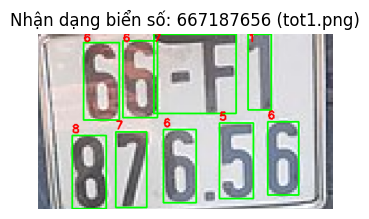

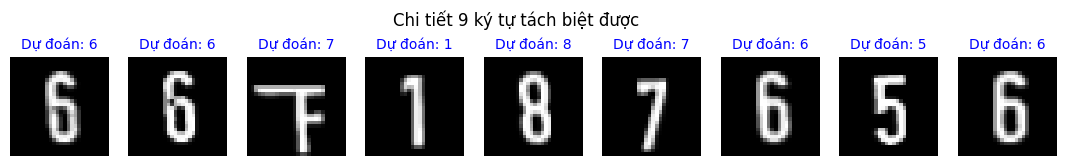

--------------------------------------------------


In [63]:
import glob
import cv2
import tensorflow as tf
import matplotlib.pyplot as plt

# Tải mô hình nhận dạng chữ số đã huấn luyện
try:
    model_rec = tf.keras.models.load_model("mnist_plate.keras")
    print("Đã tải mô hình nhận dạng mnist_base.keras thành công!")
except Exception as e:
    print("Chưa tải được mô hình nhận dạng chữ số:", e)
    model_rec = None

duong_dan_folder = "/content/bien/*.*"
danh_sach_anh = sorted(f for f in glob.glob(duong_dan_folder)
                       if f.lower().endswith(('.jpg', '.jpeg', '.png')))

if len(danh_sach_anh) == 0:
    print("Không tìm thấy ảnh nào! Bạn kiểm tra lại folder '/content/bien' nhé.")
else:
    print(f"Đã tìm thấy {len(danh_sach_anh)} ảnh. Bắt đầu xử lý và nhận dạng...\n")
    print("-" * 50)

    for p_img in danh_sach_anh:
        img_goc = cv2.imread(p_img)
        if img_goc is None:
            print(f"Không thể đọc ảnh: {p_img}")
            continue

        # Phân tách ký tự bằng hàm find_chars đã tối ưu hóa
        bw, chars, s, pad = find_chars(img_goc)
        print(f"Ảnh {p_img.split('/')[-1]}: Tìm được {len(chars)} ký tự")

        # Cắt ký tự dạng 28x28 chuẩn
        crops = crop_chars(bw, chars)
        n = len(crops)
        predictions = []

        # Nhận dạng từng ký tự bằng mô hình
        if model_rec is not None and n > 0:
            for c_img in crops:
                # Chuẩn hóa ảnh cắt đưa về khoảng [0, 1] phù hợp với MNIST
                normalized_c = c_img.astype('float32') / 255.0
                normalized_c = normalized_c[..., None] # (28, 28, 1)
                pred = model_rec.predict(normalized_c[None], verbose=0)
                predictions.append(str(pred.argmax()))

        # Ghép chuỗi thô thu được từ mô hình nhận diện
        raw_plate = "".join(predictions)
        # Áp dụng bộ lọc clean_format đã định nghĩa ở ô rswvxzUt9HKI
        try:
            cleaned_plate = clean_format(raw_plate)
        except NameError:
            cleaned_plate = raw_plate  # Fallback nếu chưa chạy ô định nghĩa hàm

        print(f" -> Biển số nhận dạng thô: {raw_plate}")
        print(f" -> Biển số chuẩn hóa:    {cleaned_plate}")

        # Vẽ bounding box lên ảnh kết quả trực quan
        vis = img_goc.copy()
        for i, box in enumerate(chars):
            x, y, w, h = to_original(box, s, pad)
            cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
            lbl = predictions[i] if i < len(predictions) else str(i+1)
            cv2.putText(vis, lbl, (x, max(y - 5, 12)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

        # Hiển thị ảnh gốc khoanh vùng
        plt.figure(figsize=(10, 5))
        plt.subplot(2, 1, 1)
        plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        plt.title(f"Nhận dạng biển số: {cleaned_plate} ({p_img.split('/')[-1]})")
        plt.axis('off')

        # Hiển thị từng ô ký tự kèm nhãn dự đoán bên dưới
        if n > 0:
            fig, axes = plt.subplots(1, n, figsize=(n * 1.5, 2)) if n > 1 else (None, [plt.gca()])
            if n == 1:
                axes = [axes] if not isinstance(axes, (list, tuple, np.ndarray)) else axes
            for i, c in enumerate(crops):
                axes[i].imshow(c, cmap='gray')
                pred_title = predictions[i] if i < len(predictions) else "?"
                axes[i].set_title(f"Dự đoán: {pred_title}", color='blue', fontsize=10)
                axes[i].axis('off')
            plt.suptitle(f"Chi tiết {n} ký tự tách biệt được")
        plt.show()
        print("-" * 50)

In [7]:
# Xóa đốm nhỏ
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
bw = cv2.morphologyEx(bw, cv2.MORPH_OPEN, kernel)   # xóa nhiễu nhỏ
bw = cv2.morphologyEx(bw, cv2.MORPH_CLOSE, kernel)  # nối nét đứt

In [62]:
# ============================================================
# FINE-TUNE CNN ĐỌC SỐ BIỂN SỐ — full pipeline
# ============================================================
import os, unicodedata, random
import numpy as np
import cv2
import tensorflow as tf

# Khởi động lại session Keras để xóa sạch các kiểu dữ liệu cũ bị cache lỗi
tf.keras.backend.clear_session()

# ---------- 1. Ground truth ----------
truth = {
    "92-la-tinh-nao-thumbnail": "92CA03484",
    "Biển_số_xe_đồng_tháp":     "66F187656",
    "Screenshot 2026-10-10 165417": "PGC1406N",
    "Screenshot 2026-10-10 165702": "50Y191255",
    "Screenshot 2026-10-10 165719": "30H45678",
    "Screenshot 2026-10-10 165808": "19F117241",
    "Screenshot 2026-10-10 165827": "35M75202",
    "tot":  "92CA03484",
    "tot1": "66F187656",
    "1791624458175_46226632464972839_g7345200886465729132_b7bb2d884a3da049ffb70242a4a45a7c": "19B121214",
}

def key(s):
    return unicodedata.normalize('NFC', os.path.splitext(os.path.basename(s))[0])

truth = {key(k): v for k, v in truth.items()}

# ---------- 2. Hàm collect ----------
def collect(names_set):
    X, y = [], []
    skipped = []
    for p_img in danh_sach_anh:
        name = key(p_img)
        if name not in names_set:
            continue
        img = cv2.imread(p_img)
        bw, chars, s, pad = find_chars(img)
        t = truth[name]
        if len(t) != len(chars):
            skipped.append((name, len(t), len(chars)))
            continue
        for c, lab in zip(crop_chars(bw, chars), t):
            if lab.isdigit(): # Đảm bảo CHỈ lấy chữ số
                X.append(c)
                y.append(int(lab))
    if skipped:
        print("  Bỏ qua (lệch số box):")
        for name, n_t, n_c in skipped:
            print(f"    {name}: truth={n_t}, detect={n_c}")

    # Ép kiểu rõ ràng phòng trường hợp mảng rỗng []
    X_arr = np.array(X, dtype=np.uint8) if len(X) > 0 else np.empty((0, 28, 28), dtype=np.uint8)
    y_arr = np.array(y, dtype=np.int64) if len(y) > 0 else np.empty((0,), dtype=np.int64)
    return X_arr, y_arr

# ---------- 3. Chia train/test THỦ CÔNG ----------
test_names  = {key("92-la-tinh-nao-thumbnail")}
train_names = set(truth.keys()) - test_names

print(f"Test:  {test_names}")
print(f"Train: {len(train_names)} ảnh\n")

# ---------- 4. Thu thập data THẬT ----------
print("=== Tập TEST ===")
X_te, y_te = collect(test_names)
print(f"  X_te: {X_te.shape}, y_te: {y_te.shape}, dtype={y_te.dtype}")
print(f"  Nhãn test: {y_te}")

print("\n=== Tập TRAIN ===")
X_real, y_real = collect(train_names)
print(f"  X_real: {X_real.shape}, y_real: {y_real.shape}")
if len(y_real) > 0:
    print(f"  Số mẫu mỗi lớp (0-9): {np.bincount(y_real, minlength=10)}")

# Kiểm tra lớp thiếu
missing = [d for d in range(10) if (y_real == d).sum() == 0]
if missing:
    print(f"  ⚠️  THIẾU LỚP: {missing} — model sẽ không học được các số này")

# ---------- 5. Augment data thật ----------
def augment(im):
    h, w = im.shape
    M = cv2.getRotationMatrix2D((w/2, h/2),
                                np.random.uniform(-8, 8),
                                np.random.uniform(0.9, 1.1))
    M[:, 2] += np.random.uniform(-2, 2, 2)
    out = cv2.warpAffine(im, M, (w, h))
    k = np.random.choice([0, 1, 2])
    if k == 1:
        out = cv2.erode(out, np.ones((2, 2), np.uint8))
    if k == 2:
        out = cv2.dilate(out, np.ones((2, 2), np.uint8))
    if np.random.rand() < 0.5:
        out = cv2.GaussianBlur(out, (3, 3), 0)
    return out

if len(X_real) > 0:
    REPEAT = 50
    Xa = np.array([augment(x) for x in X_real for _ in range(REPEAT)], dtype=np.uint8)
    ya = np.repeat(y_real, REPEAT)
else:
    Xa = np.empty((0, 28, 28), dtype=np.uint8)
    ya = np.empty((0,), dtype=np.int64)
print(f"\nSau augment: Xa={Xa.shape}, ya={ya.shape}")

# ---------- 6. Load MNIST và mix ----------
(Xm, ym), _ = tf.keras.datasets.mnist.load_data()

idx = np.random.choice(len(Xm), 3000, replace=False)   # 3000 mẫu MNIST
Xm_sel = Xm[idx]
ym_sel = ym[idx]

# Tránh việc trộn lẫn kiểu dữ liệu không đồng nhất
X = np.concatenate([Xm_sel, Xa])[..., None].astype("float32") / 255.0
y = np.concatenate([ym_sel.astype(np.int64), ya.astype(np.int64)]).astype(np.int64)

print(f"Mix X: {X.shape}, {X.dtype}")
print(f"Mix y: {y.shape}, {y.dtype}, unique={np.unique(y)}")
print(f"Bincount mix: {np.bincount(y, minlength=10)}")

# ---------- 7. Tải lại và biên dịch hoàn toàn mới mô hình gốc ----------
try:
    model_rec = tf.keras.models.load_model("mnist_base.keras")
    print("\nĐã khôi phục và tải lại mô hình mnist_base.keras hoàn chỉnh!")
except Exception as e:
    print("\nLỗi khi tải mnist_base.keras:", e)

model_rec.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

# ---------- 8. Chuẩn bị dữ liệu kiểm thử ----------
if len(X_te) > 0:
    Xt = X_te[..., None].astype("float32") / 255.0
    y_te = np.asarray(y_te, dtype=np.int64)
    print(f"\nXt: {Xt.shape}, {Xt.dtype}")
    print(f"y_te: {y_te.shape}, {y_te.dtype} — {y_te}")

# ---------- 9. Đánh giá độ chính xác TRƯỚC khi Fine-tune ----------
if len(X_te) > 0:
    print("\n=== Test TRƯỚC fine-tune ===")
    print(model_rec.evaluate(Xt, y_te, verbose=0))

# ---------- 10. Tiến hành Fine-tune ----------
print("\n=== Bắt đầu Fine-tune ===")
history = model_rec.fit(
    X, y,
    epochs=5,
    batch_size=64,
    shuffle=True,
    validation_split=0.1,
    verbose=1
)

# ---------- 11. Đánh giá độ chính xác SAU khi Fine-tune ----------
if len(X_te) > 0:
    print("\n=== Test SAU fine-tune ===")
    print(model_rec.evaluate(Xt, y_te, verbose=0))

# ---------- 12. Lưu mô hình chuyên dụng cho biển số ----------
model_rec.save("mnist_plate.keras")
print("\nĐã lưu mô hình tinh chỉnh thành công: mnist_plate.keras")

Test:  {'92-la-tinh-nao-thumbnail'}
Train: 9 ảnh

=== Tập TEST ===
  Bỏ qua (lệch số box):
    92-la-tinh-nao-thumbnail: truth=9, detect=10
  X_te: (0, 28, 28), y_te: (0,), dtype=int64
  Nhãn test: []

=== Tập TRAIN ===
  Bỏ qua (lệch số box):
    Biển_số_xe_đồng_tháp: truth=9, detect=8
    Screenshot 2026-10-10 165417: truth=8, detect=1
    Screenshot 2026-10-10 165702: truth=9, detect=6
    Screenshot 2026-10-10 165719: truth=8, detect=3
    Screenshot 2026-10-10 165827: truth=8, detect=5
    tot: truth=9, detect=10
  X_real: (16, 28, 28), y_real: (16,)
  Số mẫu mỗi lớp (0-9): [0 5 1 0 1 1 4 2 1 1]
  ⚠️  THIẾU LỚP: [0, 3] — model sẽ không học được các số này

Sau augment: Xa=(800, 28, 28), ya=(800,)
Mix X: (3800, 28, 28, 1), float32
Mix y: (3800,), int64, unique=[0 1 2 3 4 5 6 7 8 9]
Bincount mix: [304 577 362 304 320 301 500 419 344 369]

Đã khôi phục và tải lại mô hình mnist_base.keras hoàn chỉnh!

=== Bắt đầu Fine-tune ===
Epoch 1/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 118ms/step - accu

##PaddleOCR

In [4]:
!pip install paddlepaddle -q
!pip install paddleocr -q

In [5]:
import paddle
print("Paddle version:", paddle.__version__)

/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


Paddle version: 3.3.1


In [6]:
from paddleocr import PaddleOCR
ocr = PaddleOCR(use_textline_orientation=True, lang='en',enable_mkldnn=False)
print("PaddleOCR ready")

Creating model: ('PP-LCNet_x1_0_doc_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-LCNet_x1_0_doc_ori`.
Creating model: ('UVDoc', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/UVDoc`.
Creating model: ('PP-LCNet_x1_0_textline_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-LCNet_x1_0_textline_ori`.
Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP

PaddleOCR ready


In [7]:
result = ocr.predict('/content/bien/92-la-tinh-nao-thumbnail.jpg')

# In kết quả
for res in result:
    # res là dict hoặc object — tùy version
    print(res)

{'input_path': '/content/bien/92-la-tinh-nao-thumbnail.jpg', 'page_index': None, 'doc_preprocessor_res': {'input_path': None, 'page_index': None, 'input_img': array([[[178, ..., 187],
        ...,
        [ 96, ..., 129]],

       ...,

       [[182, ..., 183],
        ...,
        [ 84, ..., 115]]], dtype=uint8), 'model_settings': {'use_doc_orientation_classify': True, 'use_doc_unwarping': True}, 'angle': 0, 'rot_img': array([[[178, ..., 187],
        ...,
        [ 96, ..., 129]],

       ...,

       [[182, ..., 183],
        ...,
        [ 84, ..., 115]]], dtype=uint8), 'output_img': array([[[164, ..., 173],
        ...,
        [185, ..., 214]],

       ...,

       [[157, ..., 162],
        ...,
        [110, ..., 141]]], dtype=uint8)}, 'dt_polys': [array([[102,  80],
       ...,
       [ 91, 423]], dtype=int16), array([[  0, 360],
       ...,
       [  0, 659]], dtype=int16)], 'model_settings': {'use_doc_preprocessor': True, 'use_textline_orientation': True}, 'text_det_params': 

In [8]:
import re

def read_plate(path, ocr):
    """Đọc biển số từ ảnh. Trả về (text, conf)."""
    result = ocr.predict(path)
    if not result:
        return "", 0.0

    res = result[0]   # PaddleOCR trả list, lấy phần tử đầu
    texts = res.get('rec_texts', [])
    scores = res.get('rec_scores', [])

    if not texts:
        return "", 0.0

    # Ghép các dòng lại
    raw = "".join(texts)
    # Bỏ ký tự không phải chữ/số (dấu -, ., khoảng trắng)
    cleaned = re.sub(r'[^A-Z0-9]', '', raw.upper())
    # Confidence trung bình
    avg_conf = sum(scores) / len(scores)

    return cleaned, avg_conf

In [10]:
import re
import numpy as np

def read_plate_v2(path, ocr):
    """Đọc biển số — sort theo tọa độ y để ghép đúng thứ tự dòng."""
    result = ocr.predict(path)
    if not result:
        return "", 0.0

    res = result[0]
    texts = res.get('rec_texts', [])
    scores = res.get('rec_scores', [])
    polys = res.get('rec_polys', [])

    if not texts:
        return "", 0.0

    # Lấy tâm y của từng vùng text
    items = []
    for i, (text, score) in enumerate(zip(texts, scores)):
        if i < len(polys):
            poly = np.array(polys[i])
            cy = poly[:, 1].mean()   # tâm y
            cx = poly[:, 0].mean()   # tâm x
        else:
            cy, cx = 0, 0
        items.append((cy, cx, text, score))

    # Sort: dòng trên trước (cy nhỏ), trong cùng dòng sort theo x
    items.sort(key=lambda it: (it[0], it[1]))

    # Ghép và làm sạch
    raw = "".join(it[2] for it in items)
    cleaned = re.sub(r'[^A-Z0-9]', '', raw.upper())
    avg_conf = float(np.mean([it[3] for it in items]))

    return cleaned, avg_conf

In [12]:
def read_plate_debug(path, ocr):
    result = ocr.predict(path)
    res = result[0]
    texts = res.get('rec_texts', [])
    scores = res.get('rec_scores', [])
    polys = res.get('rec_polys', [])

    print(f"\nẢnh: {path.split('/')[-1]}")
    print(f"Số text: {len(texts)}")
    for i, (t, s) in enumerate(zip(texts, scores)):
        poly = np.array(polys[i]) if i < len(polys) else None
        if poly is not None:
            cy = poly[:, 1].mean()
            cx = poly[:, 0].mean()
            y_min, y_max = poly[:, 1].min(), poly[:, 1].max()
            print(f"  [{i}] '{t}' conf={s:.2f}  cy={cy:.1f}  cx={cx:.1f}  y_range=[{y_min},{y_max}]")
            print(f"      4 điểm: {poly.tolist()}")
        else:
            print(f"  [{i}] '{t}' conf={s:.2f}  (không có poly)")

# Chạy riêng ảnh bị đảo dòng
read_plate_debug("/content/bien/Biển_số_xe_đồng_tháp.jpg", ocr)


Ảnh: Biển_số_xe_đồng_tháp.jpg
Số text: 2
  [0] '876.56' conf=1.00  cy=65.0  cx=113.0  y_range=[38,92]
      4 điểm: [[35, 41], [190, 38], [191, 89], [36, 92]]
  [1] '66-F1' conf=1.00  cy=110.5  cx=109.5  y_range=[80,141]
      4 điểm: [[43, 84], [175, 80], [176, 137], [44, 141]]


In [17]:
import cv2

In [18]:
def read_plate_v4(path, ocr):
    img = cv2.imread(path)
    h, w = img.shape[:2]
    if min(h, w) < 1200:
        scale = 1200 / min(h, w)
        img = cv2.resize(img, None, fx=scale, fy=scale,
                         interpolation=cv2.INTER_CUBIC)
        cv2.imwrite("/tmp/up.png", img)
        path = "/tmp/up.png"

    result = ocr.predict(path)
    if not result:
        return "", 0.0
    res = result[0]
    texts = res.get('rec_texts', [])
    scores = res.get('rec_scores', [])
    polys = res.get('rec_polys', [])
    if not texts:
        return "", 0.0

    items = []
    for i, (t, s) in enumerate(zip(texts, scores)):
        cy = np.array(polys[i])[:, 1].mean() if i < len(polys) else 0
        items.append((cy, t, s))

    # Sort theo cy
    items.sort(key=lambda it: it[0])

    # Heuristic: nếu dòng đầu toàn SỐ mà dòng sau có CHỮ → đảo
    def has_letter(text):
        cleaned = re.sub(r'[^A-Z0-9]', '', text.upper())
        return any(c.isalpha() for c in cleaned)

    if len(items) >= 2:
        if not has_letter(items[0][1]) and has_letter(items[1][1]):
            items[0], items[1] = items[1], items[0]

    raw = "".join(it[1] for it in items)
    cleaned = re.sub(r'[^A-Z0-9]', '', raw.upper())
    avg_conf = float(np.mean([it[2] for it in items]))
    return cleaned, avg_conf

In [9]:
import cv2
import numpy as np
import re


VN_PATTERN = re.compile(r'^\d{2}[A-Z][A-Z0-9]?\d{4,5}$')

def is_vn_plate(text):
    return bool(VN_PATTERN.match(text))

def read_plate_final(path, ocr):
    """Đọc biển — thử cả 2 thứ tự dòng, chọn cái hợp lệ VN."""
    result = ocr.predict(path)
    if not result:
        return "", 0.0
    res = result[0]
    texts = res.get('rec_texts', [])
    scores = res.get('rec_scores', [])
    polys = res.get('rec_polys', [])

    if not texts:
        return "", 0.0

    # Lấy từng dòng với cy
    items = []
    for i, (t, s) in enumerate(zip(texts, scores)):
        cy = np.array(polys[i])[:, 1].mean() if i < len(polys) else 0
        items.append((cy, t, s))

    if len(items) == 1:
        # Chỉ 1 dòng → trả luôn
        raw = re.sub(r'[^A-Z0-9]', '', items[0][1].upper())
        return raw, float(items[0][2])

    # Sort theo cy (giả định: cy nhỏ = dòng trên)
    items.sort(key=lambda it: it[0])

    # Chuỗi làm sạch từng dòng
    def clean(t):
        return re.sub(r'[^A-Z0-9]', '', t.upper())

    top = clean(items[0][1])
    bot = "".join(clean(it[1]) for it in items[1:])
    conf = float(np.mean([it[2] for it in items]))

    # Thử 2 thứ tự
    cand1 = top + bot          # theo cy
    cand2 = bot + top          # đảo

    # Chọn cái khớp format VN
    if is_vn_plate(cand1):
        return cand1, conf
    if is_vn_plate(cand2):
        return cand2, conf

    # Không cái nào khớp → trả cái có confidence cao hơn (hoặc cand1)
    return cand1, conf

In [10]:
import glob, sys
paths = sorted(f for f in glob.glob("/content/bien/*.*")
               if f.lower().endswith(('.jpg', '.jpeg', '.png')))

for p in paths:
    text, conf = read_plate_final(p, ocr)
    is_vn = "✓" if is_vn_plate(text) else "✗"
    print(f"{p.split('/')[-1]:50s}  {text:20s}  {is_vn}  {conf:.2f}")
    sys.stdout.flush()

1791624458175_46226632464972839_g7345200886465729132_b7bb2d884a3da049ffb70242a4a45a7c.jpg  2                     ✗  0.45
92-la-tinh-nao-thumbnail.jpg                        92CA03484             ✓  1.00
Biển_số_xe_đồng_tháp.jpg                            66F187656             ✓  1.00
Screenshot 2026-10-10 165417.png                    PGC1406N              ✗  0.93
Screenshot 2026-10-10 165448.png                    EC1                   ✗  0.33
Screenshot 2026-10-10 165702.png                    91255                 ✗  1.00
Screenshot 2026-10-10 165719.png                    30H45678              ✓  0.99
Screenshot 2026-10-10 165808.png                    19                    ✗  1.00
Screenshot 2026-10-10 165827.png                    35N75202A5            ✗  0.90
tot.png                                             92CA03484             ✓  1.00
tot1.png                                            87656                 ✗  1.00


In [ ]:
import matplotlib.pyplot as plt

p = "/content/bien/Biển_số_xe_đồng_tháp.jpg"
img = cv2.imread(p)
img = cv2.resize(img, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)

result = ocr.predict(p)
res = result[0]
texts = res.get('rec_texts', [])
polys = res.get('rec_polys', [])

vis = img.copy()
for i, (t, poly) in enumerate(zip(texts, polys)):
    pts = np.array(poly, dtype=np.int32)
    cv2.polylines(vis, [pts], True, (0, 255, 0), 3)
    cv2.putText(vis, t, (int(pts[:,0].mean()) - 30, int(pts[:,1].mean())),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title(f"{p.split('/')[-1]} — {len(texts)} vùng")
plt.axis('off')
plt.show()

In [11]:
import glob

paths = sorted(f for f in glob.glob("/content/bien/*.*")
               if f.lower().endswith(('.jpg', '.jpeg', '.png')))

print(f"{'Ảnh':50s}  {'Output':20s}  {'Conf':6s}")
print("-" * 80)

for p in paths:
    text, conf = read_plate_v2(p, ocr)
    name = p.split('/')[-1]
    print(f"{name:50s}  {text:20s}  {conf:.2f}")

Ảnh                                                 Output                Conf  
--------------------------------------------------------------------------------
1791624458175_46226632464972839_g7345200886465729132_b7bb2d884a3da049ffb70242a4a45a7c.jpg  2                     0.45
92-la-tinh-nao-thumbnail.jpg                        92CA03484             1.00
Biển_số_xe_đồng_tháp.jpg                            8765666F1             1.00
Screenshot 2026-10-10 165417.png                    PGC1406N              0.93
Screenshot 2026-10-10 165448.png                    EC1                   0.33
Screenshot 2026-10-10 165702.png                    91255                 1.00
Screenshot 2026-10-10 165719.png                    30H45678              0.99
Screenshot 2026-10-10 165808.png                    19                    1.00
Screenshot 2026-10-10 165827.png                    35N75202A5            0.90
tot.png                                             92CA03484             1.00
tot1.png 